# Step 02: Exploratory Data Analysis

Every section asks a question whose answer **changes a decision** in this project.
Try each one yourself first. Hints and spoilers are folded away: click only if you're stuck.

| Section | Decision it feeds |
|---|---|
| 1. Sanity check | Is the data loaded correctly? |
| 2. Duplicates & templates | Step 04 split strategy |
| 3. Text length | Training `max_seq_length`, cost estimate |
| 4. Label balance | How to sample the ~3k tickets for labelling |
| 5. Confusable queues | Final category list (ADR-008) |
| 6. Priority | Priority levels (ADR-008) |
| 7. Entities & placeholders | `entities` field in the schema |
| 8. Agent answers | `suggested_reply` length limit |
| 9. Version effects | Whether to filter by dataset version |

Rules: `SEED = 42` everywhere; read raw examples, not just numbers.

In [55]:
import re

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_colwidth", 200)
SEED = 42

df = pd.read_json("../data/raw/tickets_en.jsonl", lines=True)
df.shape

(23618, 10)

## 1. Sanity check
- What columns and types do we have? Any missing values?
- How many tickets have an empty subject?
- Does every row have a queue, priority and type?

**Why it matters:** every later number is wrong if loading is wrong.

<details><summary>💡 Hint (click to show)</summary>

`df.head()`, `df.dtypes`, `df.isna().sum()`, `(df['subject'] == '').mean()`

</details>

**Your implication:** _..._

In [56]:
# your code
print(df.head())
print(df.dtypes)
print(df.isna().sum())
print((df['subject'] == '').mean())

             id  \
0  93b4a68e11dc   
1  964d7572a41a   
2  e78c11ec658f   
3  6ae212011a35   
4  276bf8d52f6d   

                                                                                                                                                                                                      text  \
0  Account Disruption\n\nDear Customer Support Team,\n\nI am writing to report a significant problem with the centralized account management portal, which currently appears to be offline. This outage...   
1  Query About Smart Home System Integration Features\n\nDear Customer Support Team,\n\nI hope this message reaches you well. I am reaching out to request detailed information about the capabilities ...   
2  Inquiry Regarding Invoice Details\n\nDear Customer Support Team,\n\nI hope this message finds you well. I am reaching out to request clarification about the billing and payment procedures linked t...   
3  Question About Marketing Agency Software Compatibility\n\n

## 2. Duplicates & templates
- The download script removed exact duplicates. Are there still **near-duplicates**?
- Do many tickets start the same way (templates)?
- Are agent answers reused across tickets?

**Why it matters:** if near-copies end up in both train and test, test scores lie (leakage).

<details><summary>💡 Hint (click to show)</summary>

- `df["body"].duplicated().sum()` ignores the subject.
- First lines: `df["body"].str.split("\n").str[0].value_counts().head(10)`
- Normalise before comparing: `.str.lower()`, `.str.replace(r"\s+", " ", regex=True)`, `.str.replace(r"[^\w\s]", "", regex=True)`
- Same idea on `df["answer"]`.

</details>

<details><summary>👀 Spoiler: what Claude already noticed (try first!)</summary>

The script's own output said how many exact duplicates it removed. Check your terminal or the report: it's a surprisingly large share.

</details>

**Your implication:** _..._

In [57]:
# your code
df['body'].duplicated().sum()

df['body'].str.split("\n").str[0].value_counts().head(10)

body
Request for Information on Medical Data Security                                                                                                                                                        2
A critical outage has impacted our data analytics systems, likely due to recent software updates and network disruptions.                                                                               2
Please provide details on securing medical data.                                                                                                                                                        2
Offer insights into digital strategies                                                                                                                                                                  2
Seeking details on securing medical data using OBS Studio 27 and Smart-Home-Kamera applications to maintain confidentiality and comply with regulations.                                   

In [58]:
df['body'] = df['body'].str.lower()
#df['body'] = df['body'].str.replace(r"\s+", " ", regex=True)
df['body'] = df['body'].str.replace(r"[^\w\s]", "", regex=True)
df['body'].str.split("\n").str[0].value_counts().head(10)

body
brand engagement is currently low                                                                                                                              3
facing system instability due to conflicts arising from recent updates                                                                                         2
recent invoices show unexpected billing inconsistencies                                                                                                        2
improve data analytics to optimize investment strategies                                                                                                       2
the saas platform encountered a significant outage                                                                                                             2
the saas platform encountered outages potentially due to server overload or software bugs additional server capacity was added and patches were implemented    2
share insights on digital mar

## 3. Text length
- What does the distribution of ticket length look like (characters and approx tokens)?
- Does length differ by queue?
- Training input = system prompt (~350 tokens) + ticket + JSON output (~300 tokens).
  What `max_seq_length` covers 99% of examples?

**Why it matters:** sequence length drives training memory and speed on the T4.

<details><summary>💡 Hint (click to show)</summary>

- `df["len"] = df["text"].str.len()`; tokens ≈ `len / 4`
- `df["len"].plot.hist(bins=50)`, `df["len"].quantile([0.5, 0.9, 0.99])`
- `df.groupby("queue")["len"].describe()`

</details>

**Your implication:** _..._

In [81]:
# your code
df['Len'] = df['text'].str.len()

,count,mean,std,min,25%,50%,75%,max
queue,,,,,,,,
Billing and Payments,2407.0,420.829663,208.471650,31.0,256.00,417.0,566.00,1826.0
Customer Service,3544.0,420.820542,209.538662,59.0,248.75,414.5,578.00,1715.0
General Inquiry,340.0,434.450000,204.429865,60.0,260.25,468.5,589.75,1439.0
Human Resources,459.0,396.424837,207.273242,69.0,219.00,384.0,564.50,1209.0
IT Support,2816.0,413.669744,206.024907,35.0,249.00,405.5,572.00,1532.0
Product Support,4395.0,414.741524,206.340436,44.0,250.00,409.0,572.00,1810.0
Returns and Exchanges,1169.0,417.053892,215.565967,60.0,228.00,414.0,584.00,1349.0
Sales and Pre-Sales,719.0,410.947149,208.820777,48.0,233.00,418.0,576.00,1134.0
Service Outages and Maintenance,934.0,413.229122,213.452483,37.0,238.50,419.0,565.00,1501.0


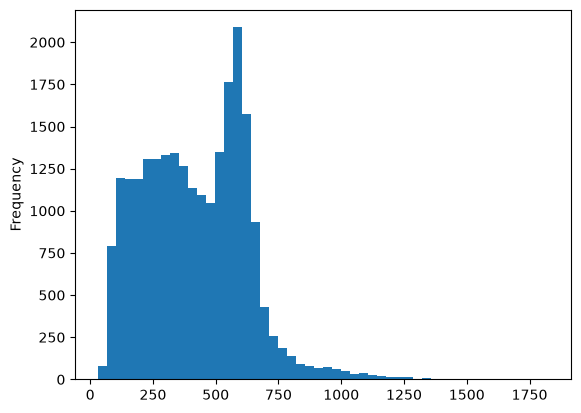

: 

In [ ]:
df['Len'].plot.hist(bins=50)
df['Len'].quantile([0.5, 0.9, 0.99])

df.groupby("queue")["Len"].describe()

## 4. Label balance
- How balanced are `queue`, `priority` and `type`?
- If we sample 3,000 tickets randomly, how many would the smallest queue get?
- Random vs stratified vs capped-per-class sampling: which would you pick?

**Why it matters:** a small model needs enough examples of rare classes, but over-sampling distorts reality.

<details><summary>💡 Hint (click to show)</summary>

- `df["queue"].value_counts().plot.barh()`
- Expected count for a class ≈ its share × 3000
- Capped sampling: `df.groupby("queue").sample(n=..., random_state=SEED)` (handle classes smaller than n)

</details>

**Your implication:** _..._

In [61]:
df.head(2)

,id,text,subject,body,answer,queue,priority,type,tags,version,Len
0,93b4a68e11dc,"Account Disruption\n\nDear Customer Support Team,\n\nI am writing to report a significant problem with the centralized account management portal, which currently appears to be offline. This outage...",Account Disruption,dear customer support teamnni am writing to report a significant problem with the centralized account management portal which currently appears to be offline this outage is blocking access to acco...,"Thank you for reaching out, <name>. We are aware of the outage affecting the centralized account management system, and our technical team is actively working to resolve the issue. In the meantime...",Technical Support,high,Incident,"[Account, Disruption, Outage, IT, Tech Support]",51.0,564
1,964d7572a41a,"Query About Smart Home System Integration Features\n\nDear Customer Support Team,\n\nI hope this message reaches you well. I am reaching out to request detailed information about the capabilities ...",Query About Smart Home System Integration Features,dear customer support teamnni hope this message reaches you well i am reaching out to request detailed information about the capabilities of your smart home integration products listed on your web...,"Thank you for your inquiry. Our products support integration with Amazon Alexa, Google Assistant, and Apple HomeKit. Compatibility details can differ depending on the specific item; please let us ...",Returns and Exchanges,medium,Request,"[Product, Feature, Tech Support]",51.0,586


queue
Technical Support                  6835
Product Support                    4395
Customer Service                   3544
IT Support                         2816
Billing and Payments               2407
Returns and Exchanges              1169
Service Outages and Maintenance     934
Sales and Pre-Sales                 719
Human Resources                     459
General Inquiry                     340
Name: count, dtype: int64

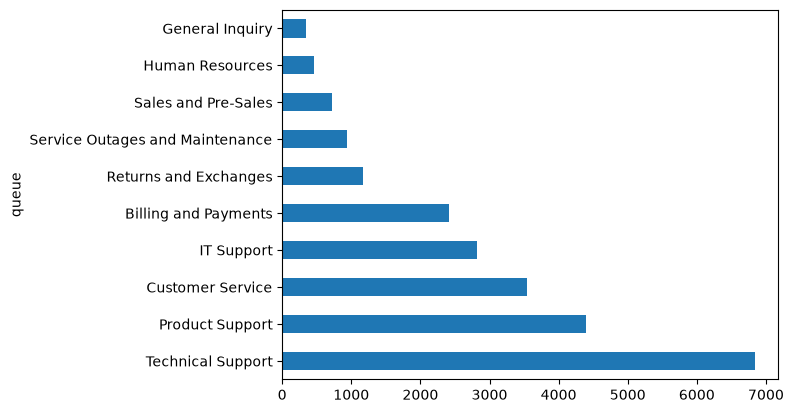

In [62]:
# your code
df['queue'].value_counts().plot.barh()
df['queue'].value_counts()

<Axes: ylabel='priority'>

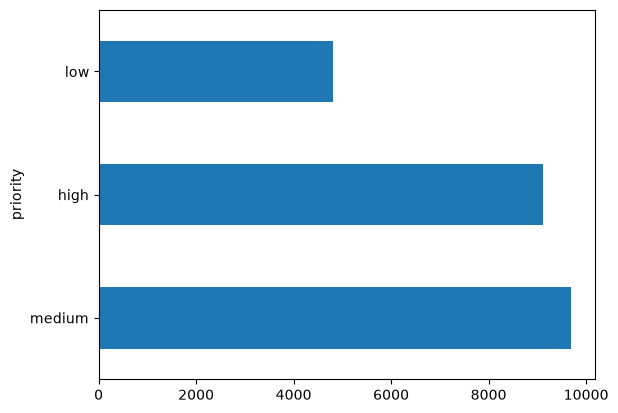

In [63]:
df['priority'].value_counts().plot.barh()

In [64]:
df.groupby('queue').sample(n=340, random_state=42)

,id,text,subject,body,answer,queue,priority,type,tags,version,Len
21717,fb73c51f846c,"Ensuring Secure Handling of Medical Data on Smart-CPAP Devices\n\nDear Customer Support, I am reaching out to seek information on the security protocols recommended for safeguarding medical data o...",Ensuring Secure Handling of Medical Data on Smart-CPAP Devices,dear customer support i am reaching out to seek information on the security protocols recommended for safeguarding medical data on smartcpap devices given that these devices store critical patient...,"At our organization, we prioritize the security of medical data on Smart-CPAP devices. Our devices are equipped with advanced security features such as encryption and secure authentication process...",Billing and Payments,high,Request,"[Security, Billing, Customer, Documentation, Guidance]",NaN,719
15660,44080558db80,Issue with Payment Discrepancies Identified\n\nThe billing system has detected discrepancies which have affected product subscriptions renewals following the recent software update. An integration...,Issue with Payment Discrepancies Identified,the billing system has detected discrepancies which have affected product subscriptions renewals following the recent software update an integration issue was reviewed and we have contacted the pa...,"Dear [Name], we apologize for the inconvenience caused by the payment discrepancy issue affecting your product subscriptions renewals. Our team is currently investigating the matter and will notif...",Billing and Payments,high,Incident,"[Billing, Payment, Refund, Bug, Performance, Feature]",400.0,277
14199,e73148d15a00,"Request to Update Payment Preferences for Marketing\n\nDear customer support, I am writing to request an update to my billing information in relation to payment preferences for software and hardwa...",Request to Update Payment Preferences for Marketing,dear customer support i am writing to request an update to my billing information in relation to payment preferences for software and hardware products used in marketing strategies i would appreci...,"<name>, we are here to assist with updating your payment preferences. To proceed with the changes, we need to verify your identity using your account number <acc_num>. Please let us know a conveni...",Billing and Payments,medium,Change,"[Billing, Payment, Update, Account, Feature, Tech Support]",400.0,593
18877,0744fd2fea50,Details on Integrating Elasticsearch with Your SaaS Platform\n\nI am keen on integrating Elasticsearch into your SaaS platform. Could you provide me with the pricing details and any necessary info...,Details on Integrating Elasticsearch with Your SaaS Platform,i am keen on integrating elasticsearch into your saas platform could you provide me with the pricing details and any necessary information to begin the process additionally i would be grateful if ...,"Hello <name>, we are grateful for your interest in our Elasticsearch integration. I will send you the required pricing details and start-up information, including any discounts that may be availab...",Billing and Payments,medium,Request,"[Technical, Billing, Integration, Feedback, Discount, Information]",NaN,382
11849,3d7601da6fce,"Request to Update Billing Information for Marketing\n\nHello Customer Support, I am writing to request an update to my billing information related to payment preferences for both software and hard...",Request to Update Billing Information for Marketing,hello customer support i am writing to request an update to my billing information related to payment preferences for both software and hardware products used in our marketing strategies i would a...,"Dear [Name], we are happy to assist you in updating your billing information and payment preferences. To make these changes, we need to verify your account number [acc_num] to confirm your identit...",Billing and Payments,medium,Change,"[Billing, Payment, Product, Feature, Tech Support, Feedback]",400.0,627
...,...,...,...,...,...,

## 5. Confusable queues (most important section)
- Are **Technical Support, IT Support, Product Support and Customer Service** really different?
- Read 5 tickets from each with the label covered. Can *you* guess the queue?
- Which words distinguish each queue?
- How well does a simple non-LLM classifier do, and which queues does it confuse?

**Why it matters:** if a human can't tell two queues apart, a model can't either; they may need merging. The simple classifier is also a **benchmark** the fine-tuned LLM must beat.

<details><summary>💡 Hint (click to show)</summary>

- `df[df.queue == q].sample(5, random_state=SEED)[["text"]]`
- Distinguishing words: `TfidfVectorizer(stop_words="english", min_df=5)`, average rows per queue, top 15 terms.
- Baseline:
  ```python
  from sklearn.feature_extraction.text import TfidfVectorizer
  from sklearn.linear_model import LogisticRegression
  from sklearn.metrics import classification_report, ConfusionMatrixDisplay
  from sklearn.model_selection import train_test_split
  from sklearn.pipeline import make_pipeline
  ```
  `ConfusionMatrixDisplay.from_predictions(y_test, y_pred, xticks_rotation=90)`

</details>

<details><summary>👀 Spoiler: what Claude already noticed (try first!)</summary>

Look at which queues the profile report puts at the top. My guess before seeing the data was that several of the big ones overlap heavily. Is that true?

</details>

**Your implication:** _..._

In [65]:
# your code
for q in ["Technical Support", "IT Support", "Product Support", "Customer Service"]:
    print(q)
    display(df[df.queue == q].sample(5, random_state=SEED)[["text"]])


Technical Support


,text
18230,Security Protocols for Medical Data Storage on Windows 10 Pro\n\nI am seeking information on the best security protocols for storing medical data on a Microsoft Windows 10 Pro system. Can you prov...
19467,"Security Protocols for Protecting Medical Data in Hospitals\n\nHello customer support, I am writing to seek information on the best security practices for safeguarding medical data within hospital..."
1484,"Digital Assistance\n\nThe digital campaign occasionally fails to upload content, which might be caused by server timeout issues. Troubleshooting steps include restarting systems and verifying netw..."
13222,Concern about unauthorized access attempts to medical data systems continuing even after password updates and firewall checks have been implemented.
18678,"Investment Data Update Problem\n\nExperience: Investment data fails to update accurately. Possible reasons: API connection problems or obsolete software. Efforts made: Restarted equipment, examine..."


IT Support


,text
3577,"Network Connectivity Concern\n\nUsers have reported sporadic connectivity problems affecting multiple services, potentially due to network instability. After restarting routers and confirming fire..."
9434,"Customer Support, exploring solutions for securing medical data in a hospital setting. Could you provide detailed information on the available options? I would like to know about the different typ..."
9625,"Problem with Delayed Notifications\n\nCustomer Support,<br>We are encountering issues with delayed notifications on our project management tool. The issue might have started after recent server up..."
20334,Enhancing Investment Tactics with H2O.ai\n\nWould it be possible to offer comprehensive guidance on optimizing investment techniques using H2O.ai data analytics to enhance return on investment?
13614,Seeking guidance on integrating ClickUp and Smartsheet to enhance project management efficiency. Would greatly appreciate step-by-step instructions and recommended resources to facilitate the inte...


Product Support


,text
21223,"Investigation Requested for Malfunction in Investment Optimization Software\n\nDear Customer Support,<br><br>I am reaching out to report a malfunction in our investment optimization software. The ..."
14270,"Request for Assistance with Marketing Campaign Performance\n\nDear Customer Support Team, I am reaching out to draw your attention to the challenges we are encountering with our marketing campaign..."
7978,Methods for Safeguarding Medical Records in Hospitals\n\nOffer details on securing medical data
2054,SaaS Platform Performance Problem\n\nCustomer Support reports a significant decline in performance of the SaaS platform under heavy load conditions. The initial assessment indicates that the probl...
22281,"Unexpected Medical Data Access Issue Sudden Today\n\nDear Customer Support,<br><br>I am contacting you to report an unexpected issue with accessing medical data. I have encountered this problem su..."


Customer Service


,text
15180,Security Protocols for Medical Data in Hospitals\n\nCould you please provide details on the security protocols used to manage medical data in hospital systems? I would like to know the measures in...
1963,"Security Incident in Healthcare System\n\nEncountering an unforeseen data security incident within the hospital. Even after implementing new security measures and rebooting the systems, the proble..."
10355,"Concern about Marketing Campaign\n\nThe marketing campaign is not performing well due to integration issues with digital tools. Despite attempts to troubleshoot by updating plugins, the problem co..."
22067,"Query on Digital Strategies for Brand Growth Online\n\nHello, I am reaching out to inquire about digital strategies that can help in brand growth online. Could you provide more details on how Zapi..."
15112,"Customer Support, the investment analysis tools used by the financial firm are experiencing malfunctions, leading to delays in data processing. The issue might be due to software compatibility pro..."


In [66]:
from sklearn.feature_extraction.text import TfidfVectorizer

vec = TfidfVectorizer(stop_words="english", min_df=5)
X = vec.fit_transform(df.text)
terms = vec.get_feature_names_out()

for q in df.queue.unique():
    rows = (df.queue == q).values
    mean_tfidf = X[rows].mean(axis=0).A1
    top = mean_tfidf.argsort()[-15:][::-1]
    print(q, terms[top])

Technical Support ['data' 'issue' 'software' 'problem' 'security' 'analytics' 'medical'
 'support' 'assistance' 'issues' 'integration' 'digital' 'project'
 'investment' 'resolve']
Returns and Exchanges ['data' 'investment' 'security' 'medical' 'analytics' 'software' 'digital'
 'information' 'issue' 'support' 'marketing' 'brand' 'integration'
 'strategies' 'management']
Billing and Payments ['billing' 'payment' 'information' 'data' 'services' 'details' 'support'
 'provide' 'security' 'medical' 'options' 'subscription' 'issue' 'pricing'
 'available']
Sales and Pre-Sales ['data' 'analytics' 'information' 'investment' 'strategies' 'brand'
 'digital' 'integration' 'solutions' 'medical' 'support' 'security' 'saas'
 'provide' 'tools']
Service Outages and Maintenance ['service' 'outage' 'outages' 'data' 'impacting' 'network' 'tools' 'issue'
 'disruptions' 'medical' 'server' 'digital' 'disruption' 'support'
 'update']
Product Support ['data' 'issue' 'security' 'analytics' 'integration' 'investm

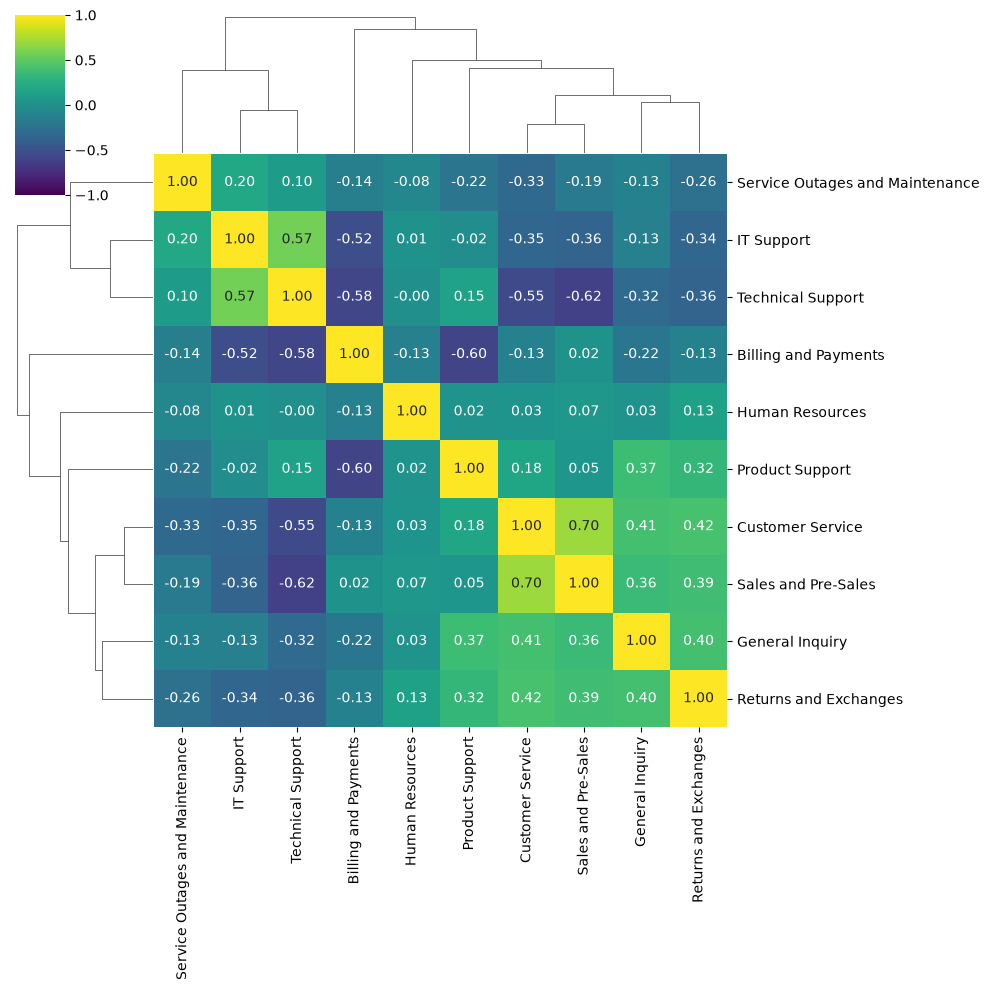

In [67]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

df = pd.read_json("../data/raw/tickets_en.jsonl", lines=True)

# TF-IDF over ticket text
vec = TfidfVectorizer(stop_words="english", min_df=5)
X = vec.fit_transform(df.text)

# one TF-IDF profile per queue, minus the overall mean so shared words ("data", "support") cancel out
queues = sorted(df.queue.unique())
overall = X.mean(axis=0).A1
profiles = np.vstack([
    X[(df.queue == q).values].mean(axis=0).A1 - overall
    for q in queues
])

# queue-by-queue cosine similarity
sim = pd.DataFrame(cosine_similarity(profiles), index=queues, columns=queues)

sns.clustermap(sim, cmap="viridis", vmin=-1, vmax=1, annot=True, fmt=".2f")
plt.show()

0.5355364573036018
                                 precision    recall  f1-score   support

           Billing and Payments       0.79      0.77      0.78       481
               Customer Service       0.50      0.56      0.53       709
                General Inquiry       0.59      0.65      0.62        68
                Human Resources       0.59      0.64      0.61        92
                     IT Support       0.49      0.55      0.52       563
                Product Support       0.54      0.50      0.52       879
          Returns and Exchanges       0.46      0.56      0.51       234
            Sales and Pre-Sales       0.44      0.60      0.51       144
Service Outages and Maintenance       0.63      0.74      0.68       187
              Technical Support       0.65      0.54      0.59      1367

                       accuracy                           0.57      4724
                      macro avg       0.57      0.61      0.59      4724
                   weighted av

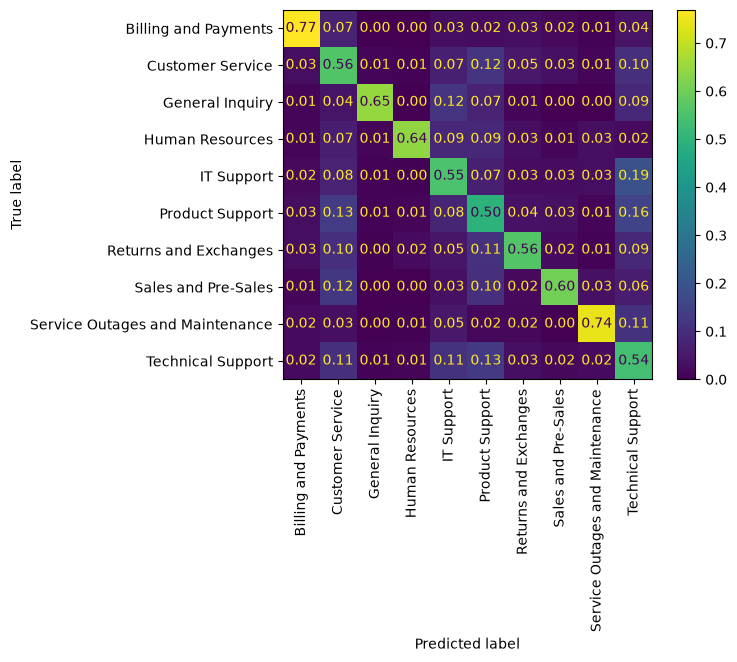

In [68]:
import numpy as np
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score, StratifiedKFold

pipe = make_pipeline(
    TfidfVectorizer(stop_words="english", min_df=5, ngram_range=(1, 2), sublinear_tf=True),
    LogisticRegression(max_iter=2000, C=3, class_weight="balanced"),
)
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
print(cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1_macro").mean())

pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_test)
print(classification_report(y_test, y_pred))

# normalise by true class so small classes are readable: each row sums to 1
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, normalize="true",
                                        xticks_rotation=90, values_format=".2f")

## 6. Priority
- Which priority levels exist in the English data? Do they match our schema's 4 levels?
- How much is priority "explained" by queue alone?
- Read 5 `high` and 5 `low` tickets: is the difference visible in the text?
- How well does the baseline from section 5 predict priority?

**Why it matters:** if priority is only predictable from the queue, the model learns a shortcut instead of reading the ticket.

<details><summary>💡 Hint (click to show)</summary>

- `df["priority"].value_counts()`
- `pd.crosstab(df.queue, df.priority, normalize="index").round(2)`
- Reuse the section 5 pipeline with `y = df["priority"]`

</details>

<details><summary>👀 Spoiler: what Claude already noticed (try first!)</summary>

Compare the priority values you find against `Priority` in `src/triage/schema.py`. They don't line up one-to-one; decide what to do about it.

</details>

**Your implication:** _..._

In [69]:
# your code
df.priority.value_counts()

priority
medium    9690
high      9114
low       4814
Name: count, dtype: int64

In [70]:
pd.crosstab(df.queue, df.priority, normalize="index").round(2)

priority,high,low,medium
queue,,,
Billing and Payments,0.29,0.21,0.49
Customer Service,0.19,0.33,0.48
General Inquiry,0.16,0.59,0.25
Human Resources,0.10,0.48,0.42
IT Support,0.47,0.10,0.43
Product Support,0.30,0.19,0.51
Returns and Exchanges,0.21,0.38,0.41
Sales and Pre-Sales,0.17,0.36,0.47
Service Outages and Maintenance,0.71,0.12,0.17


In [71]:
for q in df['priority'].unique():
    print(q)
    display(df[df.priority == q].sample(5, random_state=42)[['text']])

high


,text
16768,"Problems with Data Analytics Tool\n\nI'm encountering difficulties with the data analytics tool, which frequently crashes. The issue could be related to an incompatible integration with Zoho Books..."
16795,"Security Measures for MacBook Pro in Hospital Settings\n\nTo Whom It May Concern, I am contacting you to seek advice on the security best practices for MacBook Pro in hospital environments. Given ..."
3321,"Potential Data Security Breach\n\nAn initial investigation into a potential data security breach at one healthcare provider suggests it may have been caused by outdated encryption. Fortunately, th..."
20777,"Unexpected Crash of Data Analytics Platform During Overnight Hours\n\nRespected Customer Service Team, our data analytics platform had a sudden outage last night. Potential causes might include ex..."
4203,Safeguarding Medical Information\n\nCould you please offer best practices for protecting medical data with Symantec Endpoint Protection 14.3?


medium


,text
9512,Problem with Account Access\n\nI am unable to access my account's billing payments. This might have happened due to a system error that caused a missed payment. I have already tried resetting my p...
3844,Hospital System Data Breach Concern\n\nNoticed a possible data breach threat within hospital systems that could compromise the security of confidential medical information. This might indicate tha...
4229,"Data Access Configuration Problem\n\nCustomer support, I am reporting an issue with healthcare provider's data access. We are experiencing problems that impact multiple products, which I believe m..."
11968,Inquiry for Insights on Digital Strategies\n\nCould the Customer Support Team provide details on the digital strategies that drive brand growth? I am particularly interested in learning more about...
76,"Inquiry About Company Offerings\n\nDear Customer Support Team,\n\nI am seeking comprehensive details regarding the company's products and services. Would you be able to send brochures, pricing lis..."


low


,text
9750,"customer support, a possible security incident has been detected that involves unauthorized access attempts to medical data. this issue might arise from outdated software versions and weak access ..."
9039,Details on Integrating AutoCAD 2022 SaaS\n\nSeeking information on the integration of AutoCAD 2022 SaaS for project management. Would appreciate it if you could outline the benefits this integrati...
21277,Technical Issues with Google Meet and Discord After Installing ESET NOD32 Antivirus on Ubuntu 22.04 LTS\n\nI hope this message finds you well. I am currently experiencing problems with Google Meet...
3459,"Customer Support, I am writing to draw attention to an incident where a Product Support queue has been assigned a low priority. The problem description indicates that multiple unrelated products h..."
78,"Inconsistency in Billing Charges\n\nDear Customer Support,\n\nI am submitting a report regarding a billing inconsistency observed in the June invoice from the marketing firm. It seems there is an ..."


In [72]:
df.columns

Index(['id', 'text', 'subject', 'body', 'answer', 'queue', 'priority', 'type',
       'tags', 'version'],
      dtype='str')

## 7. Entities & placeholders
- Our schema extracts `order_id`, `product`, `account_email`, `amount`. How often does each actually appear?
- Has the data been anonymised? With what placeholder tokens?
- Is there HTML or other junk to clean?
- Are our 4 entity fields the right ones for *this* data? What would you replace them with?

**Why it matters:** if a field is almost always null, the model learns "always null", which is useless.

<details><summary>💡 Hint (click to show)</summary>

- Placeholders: `df["text"].str.findall(r"<[a-z_]+>").explode().value_counts()`
- Regexes to try with `.str.contains(...)`: money `r"\$\s?\d"`, email `r"\b[\w.-]+@[\w.-]+\.\w+\b"`, order `r"(?i)order\s*#?\s*\w*\d"`

</details>

<details><summary>👀 Spoiler: what Claude already noticed (try first!)</summary>

Run the placeholder line from the hint. Notice one token in the list isn't a placeholder at all.

</details>

**Your implication:** _..._

In [73]:
# your code
# --- 2. Is the data anonymised, and with which tokens? ---
tokens = df["text"].str.findall(r"<[a-z_]+>").explode().value_counts()
print(tokens)                                   # one of these won't be a placeholder
print((df["text"].str.contains(r"<[a-z_]+>")).mean(), "of tickets contain a <token>")
    

text
<br>             2521
<tel_num>         288
<acc_num>          64
<name>             18
<email>             3
<ref_num>           1
<website_url>       1
<user>              1
Name: count, dtype: int64
0.03408417308832246 of tickets contain a <token>


In [74]:
# --- 3. HTML or other junk ---
html_tags = {"br", "p", "div", "span", "a", "b", "i", "li", "ul", "table", "img"}
print(tokens[tokens.index.str.strip("<>").isin(html_tags)])   # HTML tags hiding in the list
print(df["text"].str.contains(r"&[a-z]+;|&#\d+;").mean(), "have HTML entities")
print(df["text"].str.contains(r"\\n|\r|\t").mean(), "have raw escapes")
print(df["text"].str.contains(r"https?://").mean(), "have URLs")
print(df["text"].str.len().describe())          # very short or very long texts

# --- 4. Which fields fit this data? Find what the placeholders already tell you ---
tokens.head(15)
# Also sample real tickets and read them:
for t in df["text"].sample(10, random_state=1):
    print("-", t[:300].replace("\n", " "), "\n")

text
<br>    2521
Name: count, dtype: int64
0.0 have HTML entities
0.041451435345922605 have raw escapes
0.0 have URLs
count    23618.000000
mean       418.310568
std        206.883472
min         30.000000
25%        250.000000
50%        415.000000
75%        574.000000
max       1826.000000
Name: text, dtype: float64
- Reported Data Breach Due to Outdated Elasticsearch  Hello Customer Support, I am contacting you to report a data breach that has taken place. This issue may be related to an outdated Elasticsearch system. Despite my efforts to restart Elasticsearch, the problem continues to persist without a resolut 

- Scheduled Uptime Maintenance Procedures  Dear Customer Support, I am seeking guidance on best practices for maintaining uptime during scheduled maintenance of our SaaS platform. Could you share general advice or recommendations to reduce downtime and ensure a smooth experience for users? I would be  

- Request for Mailchimp Integration  Hello Customer Support, I am wr

## 8. Agent answers
- How long are the agent `answer`s?
- What's their tone and structure? Do they promise things (refunds, timelines)?
- Is `max_length=1200` for `suggested_reply` right? Should the teacher imitate this style?

**Why it matters:** reply length is the biggest driver of output tokens: cost, latency, and training time.

<details><summary>💡 Hint (click to show)</summary>

`df['answer'].str.len().describe()`, then read `df['answer'].sample(5, random_state=SEED)`

</details>

**Your implication:** _..._

In [75]:
# your code
df.answer.str.len().describe()

count    23613.000000
mean       374.625418
std        181.088390
min          4.000000
25%        220.000000
50%        373.000000
75%        519.000000
max       1315.000000
Name: answer, dtype: float64

In [76]:
df.answer.sample(5, random_state=SEED)

4954                                                           Examine the server overload and configuration issues impacting the critical products. Contact us at <tel_num> to discuss and provide a solution.
6151    Dear customer, we appreciate your interest in our digital brand growth services. We would be delighted to provide you with information on our strategies and offer a range of services including soc...
4139    We have received your message regarding slow loading times on the project dashboard. Please conduct a thorough investigation, especially considering the recent changes to the database schema. To a...
1493                                                                   Please review the issue by contacting <tel_num>. Discuss the situation, gather additional information, and facilitate the investigation.
9222    Thank you for reaching out to our support team regarding the optimization of Jira Software. We will provide guidance on streamlining workflows, customizing dash

## 9. Version effects
- Which dataset versions are mixed in, and how many rows are missing a version?
- Do queue / priority distributions or text lengths differ by version?
- Keep all versions, or filter?

**Why it matters:** mixing releases built with different generators can add inconsistent labels.

<details><summary>💡 Hint (click to show)</summary>

- `df["version"].value_counts(dropna=False)`
- `pd.crosstab(df.version.fillna(-1), df.queue, normalize="index").round(2)`

</details>

**Your implication:** _..._

In [77]:
# your code
df.version.value_counts(dropna=False)

version
400.0    10385
NaN       7361
52.0      5321
51.0       551
Name: count, dtype: int64

In [78]:
pd.crosstab(df.version.fillna(-1), df.queue, normalize="index").round(2)

queue,Billing and Payments,Customer Service,General Inquiry,Human Resources,IT Support,Product Support,Returns and Exchanges,Sales and Pre-Sales,Service Outages and Maintenance,Technical Support
version,,,,,,,,,,
-1.0,0.11,0.16,0.01,0.02,0.12,0.18,0.05,0.03,0.04,0.29
51.0,0.08,0.14,0.02,0.02,0.10,0.21,0.03,0.04,0.05,0.31
52.0,0.09,0.14,0.01,0.02,0.13,0.20,0.05,0.03,0.04,0.29
400.0,0.10,0.15,0.01,0.02,0.11,0.18,0.05,0.03,0.04,0.29


## Summary → copy into `docs/steps/02-dataset.md` Findings
1. Near-duplicates:
2. Max sequence length:
3. Sampling strategy:
4. Final categories:
5. Priority levels:
6. Entity fields:
7. Reply length:
8. Versions: